# Mini Project 2.2 — OFDM Waveform Generator with a Cyclic Prefix Visualizer

**Course:** Mobile Communications — Unit 2 Lab
**Tools:** Python 3, NumPy (`numpy.fft` for IFFT/FFT, `numpy.convolve` for the channel), Matplotlib. No toolbox or SDR hardware is needed.

**Objective.** Build a small but complete OFDM transmitter and receiver: Gray-coded QAM → N-subcarrier IFFT → cyclic prefix (CP)
→ synthetic multipath channel → CP removal → FFT → one-tap equalizer → decisions. Then show directly that a CP longer than the channel's
delay spread removes inter-symbol interference (ISI), and that a missing or too-short CP does not.

The notebook follows the manual's **Suggested Approach** steps 1–8 in order. A checklist against the requirements and the evaluation criteria is at the end.

## 0. System parameters
The numbers are chosen to resemble IEEE 802.11a/g. N = 64 subcarriers at a 20 MHz sample rate gives a 3.2 µs useful symbol,
and the standard CP of N/4 = 16 samples is 0.8 µs. That makes delays easy to read in both samples and microseconds.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(1)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
import os; FIG_DIR = "figures_2_2"; os.makedirs(FIG_DIR, exist_ok=True)

N = 64              # subcarriers (FFT size)
M = 16              # 16-QAM (set M = 4 for QPSK; the whole notebook works with either)
k = int(np.log2(M)) # bits per subcarrier symbol
FS = 20e6           # sample rate, Hz -> 50 ns per sample
TS = 1/FS
N_SYM = 400         # consecutive OFDM symbols sent back-to-back through the channel
CP_GOOD = 16        # "sufficient" CP  (N/4, 0.8 us)
CP_SHORT = 4        # "insufficient" CP (0.2 us)
print(f"Useful symbol time = {N*TS*1e6:.1f} us, sample period = {TS*1e9:.0f} ns, "
      f"bits per OFDM symbol = {N*k}")

Useful symbol time = 3.2 us, sample period = 50 ns, bits per OFDM symbol = 256


## Step 1 — constellation mapper, built and unit-tested first
Square Gray-coded M-QAM: half of each bit group chooses the in-phase level and the other half the quadrature level. Each half is Gray-decoded to a level index, so neighbouring
points differ by exactly one bit. Average symbol energy is normalised to 1. The demapper is the minimum-distance rule.

16-QAM mapper: bits->symbols->bits round trip OK, Es = 1.000, Gray property OK, d_min = 0.6325


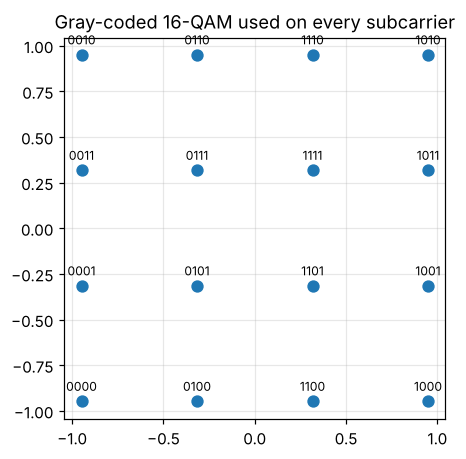

In [2]:
def gray_to_binary(g):
    b = g.copy(); s = g >> 1
    while np.any(s):
        b ^= s; s >>= 1
    return b

def qam_constellation(M):
    k = int(np.log2(M)); h = k//2; L = 2**h
    idx = np.arange(M)
    li = 2*gray_to_binary(idx >> h) - (L-1)
    lq = 2*gray_to_binary(idx & (L-1)) - (L-1)
    pts = li + 1j*lq
    return pts/np.sqrt(np.mean(np.abs(pts)**2))

PTS = qam_constellation(M)
WEIGHTS = 1 << np.arange(k-1, -1, -1)

def map_bits(bits):
    return PTS[bits.reshape(-1, k) @ WEIGHTS]

def demap_symbols(sym):
    idx = np.argmin(np.abs(sym[:, None] - PTS[None, :]), axis=1)
    bits = ((idx[:, None] >> np.arange(k-1, -1, -1)) & 1).reshape(-1)
    return idx, bits

# ---------------- unit tests ----------------
b_test = np.random.randint(0, 2, 4000*k)
s_test = map_bits(b_test)
_, b_back = demap_symbols(s_test)
assert np.array_equal(b_back, b_test), "round trip failed"
assert abs(np.mean(abs(PTS)**2) - 1) < 1e-12, "energy not normalised"
dmin = np.min(abs(PTS[:, None]-PTS[None, :])[~np.eye(M, dtype=bool)])
gray_ok = all(bin(i ^ j).count("1") == 1 for i in range(M) for j in range(M)
              if i != j and abs(abs(PTS[i]-PTS[j]) - dmin) < 1e-9)
assert gray_ok, "not Gray coded"
print(f"{M}-QAM mapper: bits->symbols->bits round trip OK, Es = {np.mean(abs(PTS)**2):.3f}, "
      f"Gray property OK, d_min = {dmin:.4f}")

fig, ax = plt.subplots(figsize=(4.5, 4.5))
ax.scatter(PTS.real, PTS.imag, s=50)
for i, p in enumerate(PTS):
    ax.annotate(format(i, f"0{k}b"), (p.real, p.imag), xytext=(0, 7), textcoords="offset points", ha="center", fontsize=8)
ax.set_aspect("equal"); ax.set_title(f"Gray-coded {M}-QAM used on every subcarrier")
plt.savefig(f"{FIG_DIR}/step1_constellation.png", bbox_inches="tight"); plt.show()

## Step 2 — IFFT modulator and a noiseless self-check
One OFDM symbol is a vector $X[0..N-1]$ of subcarrier values. The time-domain waveform is $x = \text{IFFT}(X)$. The factor $\sqrt N$ makes the transform pair unitary,
so time-domain and frequency-domain energy are equal. The self-check FFTs our own IFFT output and confirms that the original subcarrier values come back exactly.

Noiseless self-check: max |FFT(IFFT(X)) - X| = 4.58e-16  ->  PASS
Energy check: sum|X|^2 = 72.0000, sum|x|^2 = 72.0000
Recovered bits identical: True
PAPR of this symbol = 7.3 dB (OFDM's well-known high peak-to-average ratio)


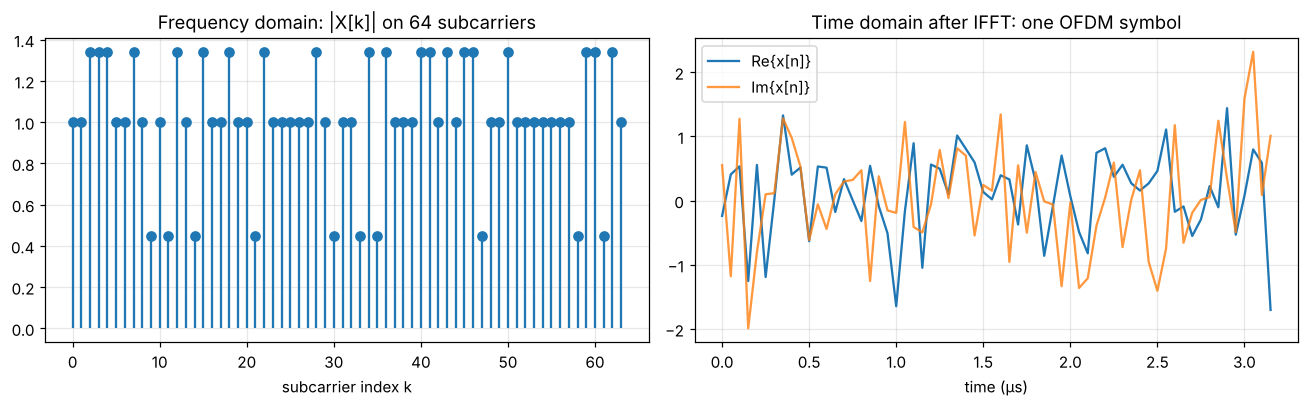

In [3]:
def ofdm_modulate(X):          # X: (..., N) subcarrier values -> time samples
    return np.fft.ifft(X, axis=-1) * np.sqrt(N)

def ofdm_demodulate(x):        # x: (..., N) time samples -> subcarrier values
    return np.fft.fft(x, axis=-1) / np.sqrt(N)

bits1 = np.random.randint(0, 2, N*k)
X1 = map_bits(bits1)
x1 = ofdm_modulate(X1)
X1_back = ofdm_demodulate(x1)
err = np.max(np.abs(X1_back - X1))
print(f"Noiseless self-check: max |FFT(IFFT(X)) - X| = {err:.2e}  ->  {'PASS' if err < 1e-12 else 'FAIL'}")
print(f"Energy check: sum|X|^2 = {np.sum(abs(X1)**2):.4f}, sum|x|^2 = {np.sum(abs(x1)**2):.4f}")
_, bb = demap_symbols(X1_back); print("Recovered bits identical:", np.array_equal(bb, bits1))
papr = 10*np.log10(np.max(abs(x1)**2)/np.mean(abs(x1)**2))
print(f"PAPR of this symbol = {papr:.1f} dB (OFDM's well-known high peak-to-average ratio)")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].stem(np.arange(N), abs(X1), basefmt=" "); axes[0].set_title("Frequency domain: |X[k]| on 64 subcarriers")
axes[0].set_xlabel("subcarrier index k")
t_us = np.arange(N)*TS*1e6
axes[1].plot(t_us, x1.real, label="Re{x[n]}"); axes[1].plot(t_us, x1.imag, label="Im{x[n]}", alpha=0.8)
axes[1].set_title("Time domain after IFFT: one OFDM symbol"); axes[1].set_xlabel("time (µs)"); axes[1].legend()
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/step2_ifft_symbol.png", bbox_inches="tight"); plt.show()

## Step 3 — cyclic prefix insertion (and the CP visualizer)
The CP is a copy of the last $L_{CP}$ samples of the symbol placed in front of it. The check confirms that the prefix equals the tail.
The plot shows **three consecutive CP-OFDM symbols**. The shaded blocks are the prefixes, and the same-coloured blocks at each symbol's end are the samples they were copied from.

CP length 16: symbol length 64 -> 80 samples
Prefix equals the last 16 samples: True
Body after the prefix is the original symbol: True


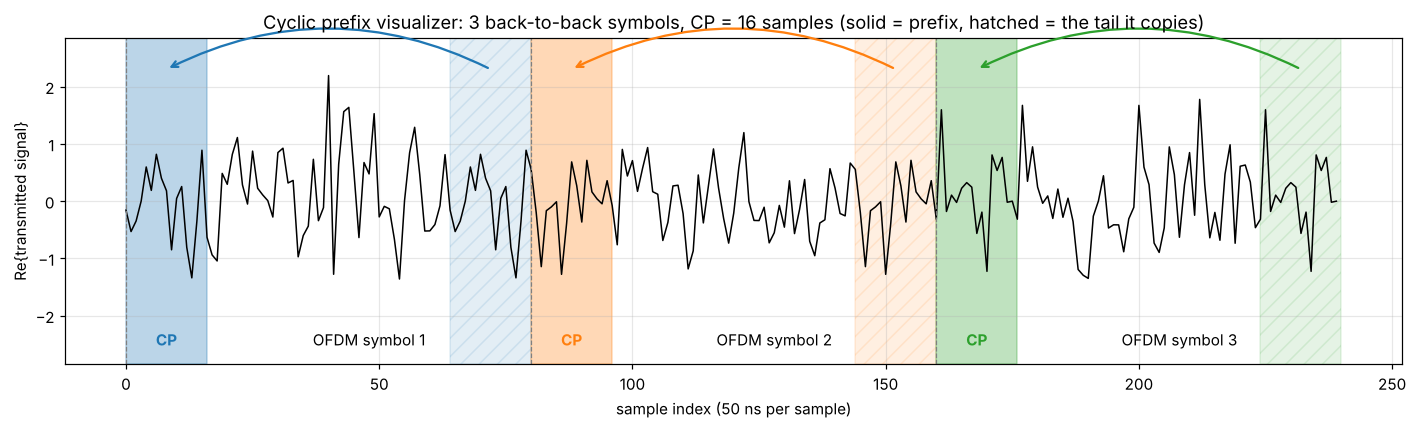

In [4]:
def add_cp(x, Lcp):            # x: (..., N)
    return np.concatenate([x[..., N-Lcp:], x], axis=-1) if Lcp > 0 else x.copy()

def remove_cp(y, Lcp):
    return y[..., Lcp:]

xc = add_cp(x1, CP_GOOD)
print(f"CP length {CP_GOOD}: symbol length {N} -> {xc.size} samples")
print("Prefix equals the last", CP_GOOD, "samples:", np.array_equal(xc[:CP_GOOD], x1[-CP_GOOD:]))
print("Body after the prefix is the original symbol:", np.array_equal(xc[CP_GOOD:], x1))

# CP visualizer: 3 consecutive symbols
X3 = map_bits(np.random.randint(0, 2, 3*N*k)).reshape(3, N)
tx3 = add_cp(ofdm_modulate(X3), CP_GOOD).reshape(-1)
Ls = N + CP_GOOD
fig, ax = plt.subplots(figsize=(13, 4))
n = np.arange(tx3.size)
ax.plot(n, tx3.real, color="k", lw=1)
cols = ["tab:blue", "tab:orange", "tab:green"]
for m in range(3):
    s0 = m*Ls
    ax.axvspan(s0, s0+CP_GOOD, color=cols[m], alpha=0.30)
    ax.axvspan(s0+Ls-CP_GOOD, s0+Ls, color=cols[m], alpha=0.12, hatch="//")
    ytop = 1.05*np.max(abs(tx3.real))
    ax.annotate("", xy=(s0+CP_GOOD/2, ytop), xytext=(s0+Ls-CP_GOOD/2, ytop),
                arrowprops=dict(arrowstyle="->", color=cols[m], lw=1.5, connectionstyle="arc3,rad=0.25"))
    ax.text(s0+CP_GOOD/2, -1.15*np.max(abs(tx3.real)), "CP", ha="center", color=cols[m], fontweight="bold")
    ax.text(s0+CP_GOOD+N/2, -1.15*np.max(abs(tx3.real)), f"OFDM symbol {m+1}", ha="center")
    ax.axvline(s0, color="gray", lw=0.8, ls="--")
ax.set_ylim(-1.3*np.max(abs(tx3.real)), 1.3*np.max(abs(tx3.real)))
ax.set_xlabel("sample index (50 ns per sample)"); ax.set_ylabel("Re{transmitted signal}")
ax.set_title(f"Cyclic prefix visualizer: 3 back-to-back symbols, CP = {CP_GOOD} samples "
             f"(solid = prefix, hatched = the tail it copies)")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/step3_cp_visualizer.png", bbox_inches="tight"); plt.show()

## Step 4 — synthetic multipath channel
The channel is a 4-tap FIR filter with fixed delays and complex gains, normalised to unit total power. It is applied with `numpy.convolve` to the whole stream of back-to-back
CP-OFDM symbols, so the tail of each symbol really spills into the next one.

| tap | delay (samples) | delay (ns) | complex gain |
|---|---|---|---|
| 0 | 0 | 0 | 1.0 |
| 1 | 2 | 100 | 0.60·e^{j0.7} |
| 2 | 5 | 250 | 0.40·e^{−j1.9} |
| 3 | 9 | 450 | 0.30·e^{j2.6} |

The **maximum excess delay** is 9 samples (450 ns), so a CP of at least 9 samples is required. CP = 16 is sufficient, and CP = 4 is too short.

max excess delay = 9 samples = 450 ns
RMS delay spread = 2.41 samples = 121 ns
coherence bandwidth ~ 1/(5*tau_rms) = 1.7 MHz vs subcarrier spacing 312.5 kHz
|H[k]| over the 64 subcarriers: min 0.163, max 1.559 (no deep null -> one-tap ZF is safe)


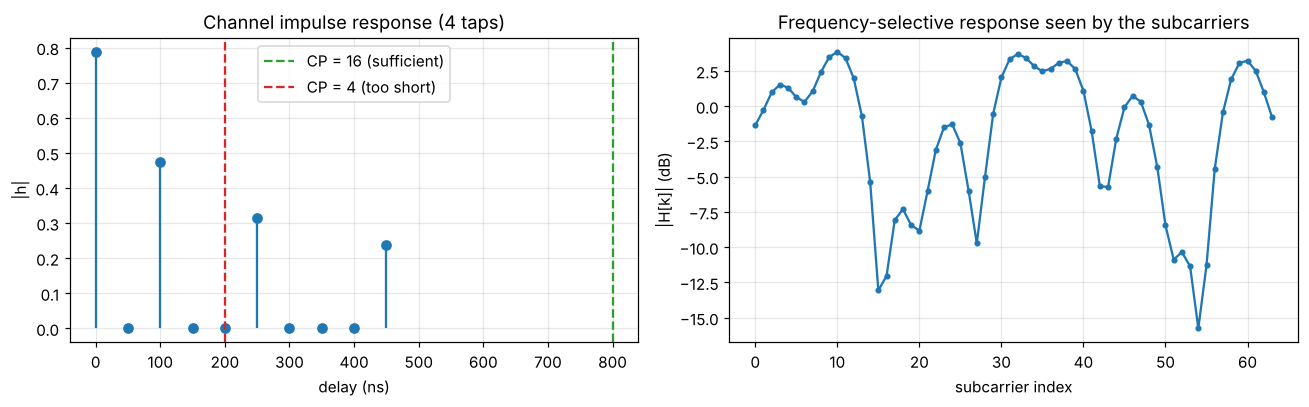

In [5]:
delays = np.array([0, 2, 5, 9])
gains = np.array([1.0, 0.6*np.exp(1j*0.7), 0.4*np.exp(-1j*1.9), 0.3*np.exp(1j*2.6)])
h = np.zeros(delays.max()+1, complex); h[delays] = gains
h /= np.sqrt(np.sum(abs(h)**2))               # unit power -> no average gain/loss
TAU_MAX = delays.max()                        # samples

p = abs(h[delays])**2
tau_mean = np.sum(p*delays)/np.sum(p)
tau_rms = np.sqrt(np.sum(p*(delays-tau_mean)**2)/np.sum(p))
H = np.fft.fft(h, N)                          # channel frequency response on the subcarriers
print(f"max excess delay = {TAU_MAX} samples = {TAU_MAX*TS*1e9:.0f} ns")
print(f"RMS delay spread = {tau_rms:.2f} samples = {tau_rms*TS*1e9:.0f} ns")
print(f"coherence bandwidth ~ 1/(5*tau_rms) = {1/(5*tau_rms*TS)/1e6:.1f} MHz vs subcarrier spacing {FS/N/1e3:.1f} kHz")
print(f"|H[k]| over the 64 subcarriers: min {abs(H).min():.3f}, max {abs(H).max():.3f} (no deep null -> one-tap ZF is safe)")

def channel(tx, h, snr_dB=None):
    y = np.convolve(tx, h)[:tx.size]          # linear convolution, truncated to the stream length
    if snr_dB is not None:                    # optional AWGN (average signal power is 1)
        n0 = 10**(-snr_dB/10)
        y = y + np.sqrt(n0/2)*(np.random.randn(y.size) + 1j*np.random.randn(y.size))
    return y

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].stem(np.arange(h.size)*TS*1e9, abs(h), basefmt=" ")
axes[0].set_xlabel("delay (ns)"); axes[0].set_ylabel("|h|"); axes[0].set_title("Channel impulse response (4 taps)")
axes[0].axvline(CP_GOOD*TS*1e9, color="tab:green", ls="--", label=f"CP = {CP_GOOD} (sufficient)")
axes[0].axvline(CP_SHORT*TS*1e9, color="tab:red", ls="--", label=f"CP = {CP_SHORT} (too short)")
axes[0].legend()
axes[1].plot(np.arange(N), 20*np.log10(abs(H)), "o-", ms=3)
axes[1].set_xlabel("subcarrier index"); axes[1].set_ylabel("|H[k]| (dB)")
axes[1].set_title("Frequency-selective response seen by the subcarriers")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/step4_channel.png", bbox_inches="tight"); plt.show()

**Why the CP matters, shown numerically.** Over the receiver's window, a channel acts as a *linear* convolution. The FFT can only undo a *circular* convolution,
which is the property that turns the channel into a simple multiplication $Y[k] = H[k]X[k]$. The check below shows that after CP removal the received block equals
the circular convolution of the transmitted symbol with $h$ exactly when $L_{CP} \ge$ the maximum excess delay. With a shorter CP it does not.

In [6]:
x_single = ofdm_modulate(map_bits(np.random.randint(0, 2, N*k)))
circ = np.fft.ifft(np.fft.fft(x_single)*H)                     # ideal circular convolution
for Lcp in [0, 4, 8, 9, 16]:
    rx = np.convolve(add_cp(x_single, Lcp), h)[:N+Lcp]          # linear conv of ONE symbol
    d = np.max(abs(remove_cp(rx, Lcp) - circ))
    print(f"CP = {Lcp:>2}: max |linear-after-CP-removal - circular| = {d:.2e}  "
          f"-> {'equal (circular)' if d < 1e-12 else 'NOT circular'}")

CP =  0: max |linear-after-CP-removal - circular| = 7.71e-01  -> NOT circular
CP =  4: max |linear-after-CP-removal - circular| = 6.33e-01  -> NOT circular
CP =  8: max |linear-after-CP-removal - circular| = 5.31e-01  -> NOT circular
CP =  9: max |linear-after-CP-removal - circular| = 5.24e-16  -> equal (circular)
CP = 16: max |linear-after-CP-removal - circular| = 5.24e-16  -> equal (circular)


## Step 5 — CP-aware receiver: near-perfect recovery when CP > delay spread
Receiver chain: cut the stream into blocks of $N+L_{CP}$ → discard the first $L_{CP}$ samples → FFT → one-tap zero-forcing equalizer $\hat X[k] = Y[k]/H[k]$
(perfect channel knowledge is assumed, so any remaining error comes only from ISI/ICI) → minimum-distance decisions.

In [7]:
def transmit(bits, Lcp):
    X = map_bits(bits).reshape(-1, N)
    tx = add_cp(ofdm_modulate(X), Lcp).reshape(-1)
    return X, tx

def receive(y, Lcp):
    blocks = y.reshape(-1, N+Lcp)
    Y = ofdm_demodulate(remove_cp(blocks, Lcp))
    return Y / H[None, :]                     # one-tap equaliser per subcarrier

def run_link(Lcp, snr_dB=None, bits=None):
    X, tx = transmit(bits, Lcp)
    Xhat = receive(channel(tx, h, snr_dB), Lcp)
    idx_hat, bits_hat = demap_symbols(Xhat.reshape(-1))
    idx_tx, _ = demap_symbols(X.reshape(-1))
    return dict(Xhat=Xhat, X=X,
                ser=np.mean(idx_hat != idx_tx),
                ber=np.mean(bits_hat != bits),
                mse=np.mean(abs(Xhat - X)**2))

data_bits = np.random.randint(0, 2, N_SYM*N*k)    # the SAME data is used for every case below
res_good = run_link(CP_GOOD, bits=data_bits)
print(f"CP = {CP_GOOD} (> {TAU_MAX}-sample delay spread), noiseless, {N_SYM} consecutive symbols:")
print(f"   SER = {res_good['ser']:.2e},  BER = {res_good['ber']:.2e},  MSE = {res_good['mse']:.2e}")
print("   -> recovery is perfect to floating-point precision")

CP = 16 (> 9-sample delay spread), noiseless, 400 consecutive symbols:
   SER = 0.00e+00,  BER = 0.00e+00,  MSE = 1.60e-31
   -> recovery is perfect to floating-point precision


## Step 6 — no CP and too-short CP on the identical channel
Same data bits, same channel taps, same receiver; only the CP length changes.

In [8]:
res_short = run_link(CP_SHORT, bits=data_bits)
res_none = run_link(0, bits=data_bits)
print(f"{'case':<26}{'SER':>10}{'BER':>11}{'MSE':>11}{'MSE (dB)':>10}")
for name, r in [(f"CP = {CP_GOOD} (sufficient)", res_good), (f"CP = {CP_SHORT} (too short)", res_short), ("CP = 0 (no CP)", res_none)]:
    print(f"{name:<26}{r['ser']:>10.2e}{r['ber']:>11.2e}{r['mse']:>11.2e}{10*np.log10(r['mse']+1e-300):>10.1f}")

case                             SER        BER        MSE  MSE (dB)
CP = 16 (sufficient)        0.00e+00   0.00e+00   1.60e-31    -308.0
CP = 4 (too short)          5.52e-02   1.52e-02   3.82e-02     -14.2
CP = 0 (no CP)              1.76e-01   5.27e-02   1.39e-01      -8.6


### Where the damage comes from: isolating the ISI
Because the system is linear, the leakage can be measured directly. Send **only symbol 1** (all other symbols zero) and look at what lands in **symbol 2's FFT window**
after the receiver discards the CP. Anything there is pure ISI.

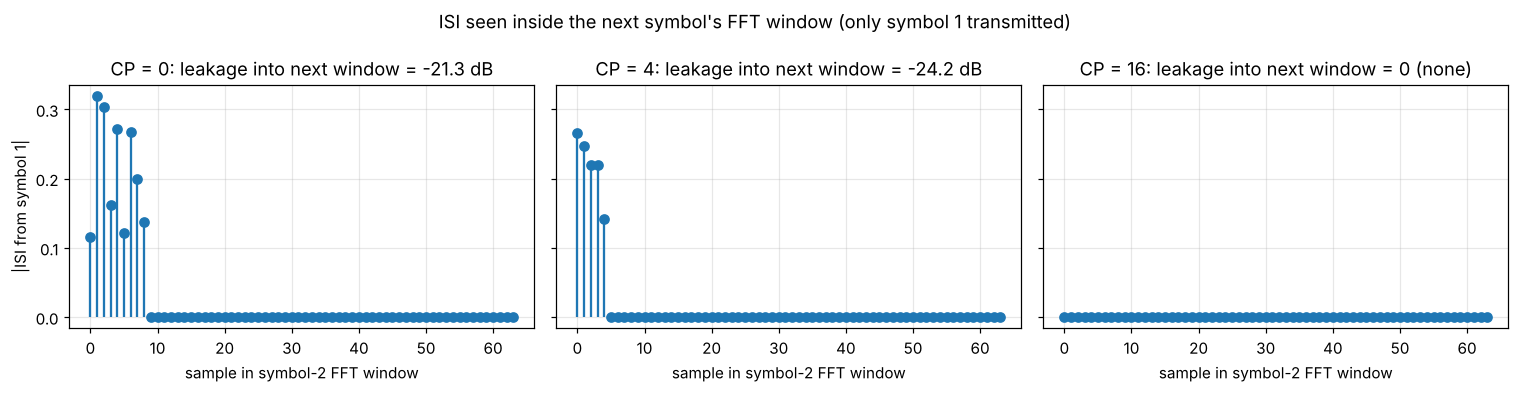

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.6), sharey=True)
for ax, Lcp in zip(axes, [0, CP_SHORT, CP_GOOD]):
    Xo = np.zeros((3, N), complex); Xo[0] = map_bits(np.random.randint(0, 2, N*k))
    y = np.convolve(add_cp(ofdm_modulate(Xo), Lcp).reshape(-1), h)[:3*(N+Lcp)]
    win2 = remove_cp(y.reshape(3, N+Lcp), Lcp)[1]          # symbol 2's FFT window
    leak = np.sum(abs(win2)**2) / np.sum(abs(ofdm_modulate(Xo[0]))**2)
    ax.stem(np.arange(N), abs(win2), basefmt=" ")
    ax.set_title(f"CP = {Lcp}: leakage into next window = "
                 + (f"{10*np.log10(leak):.1f} dB" if leak > 1e-25 else "0 (none)"))
    ax.set_xlabel("sample in symbol-2 FFT window")
axes[0].set_ylabel("|ISI from symbol 1|")
fig.suptitle("ISI seen inside the next symbol's FFT window (only symbol 1 transmitted)")
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/step6_isi_leakage.png", bbox_inches="tight"); plt.show()

## Step 7 — core visualizations
### 7a. Recovered constellations, same channel and same data

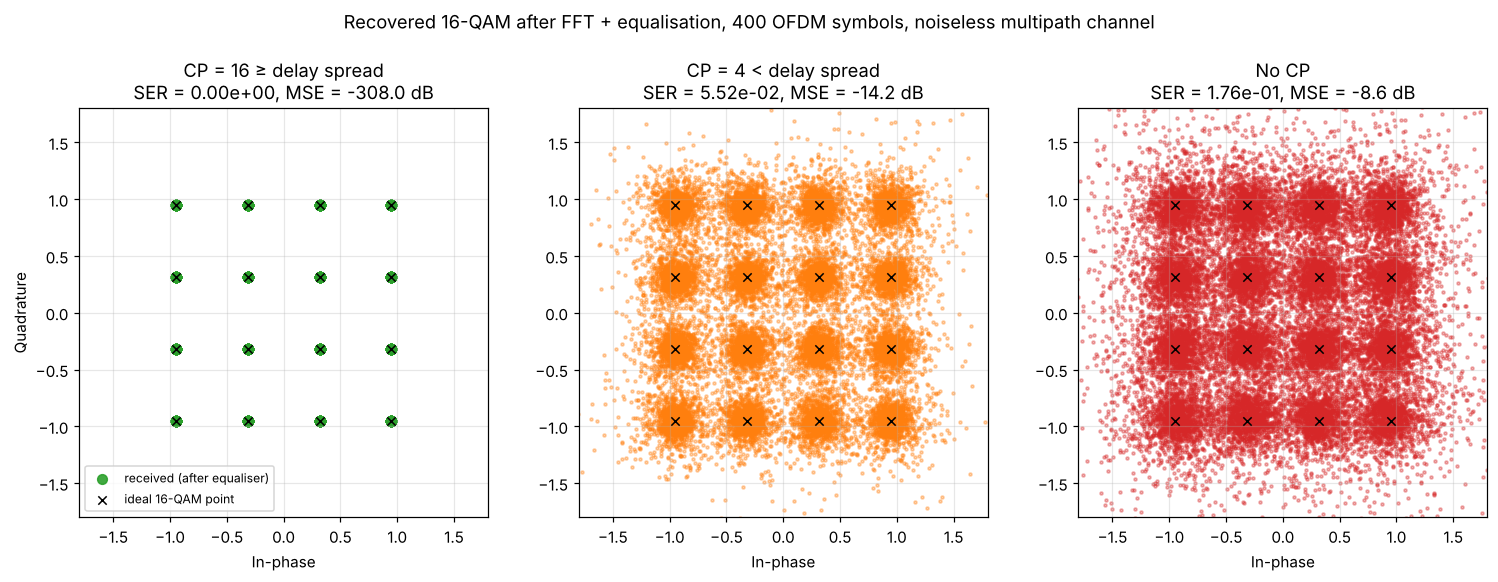

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.8))
for ax, (title, r, c) in zip(axes, [(f"CP = {CP_GOOD} ≥ delay spread", res_good, "tab:green"),
                                    (f"CP = {CP_SHORT} < delay spread", res_short, "tab:orange"),
                                    ("No CP", res_none, "tab:red")]):
    z = r["Xhat"].reshape(-1)
    ax.scatter(z.real, z.imag, s=4 if r["mse"] > 1e-12 else 40, alpha=0.35 if r["mse"] > 1e-12 else 0.9, color=c,
               label="received (after equaliser)")
    ax.scatter(PTS.real, PTS.imag, marker="x", s=30, color="k", lw=1, label="ideal 16-QAM point")
    ax.set_aspect("equal"); ax.set_xlim(-1.8, 1.8); ax.set_ylim(-1.8, 1.8)
    ax.set_title(f"{title}\nSER = {r['ser']:.2e}, MSE = {10*np.log10(r['mse']+1e-300):.1f} dB")
    ax.set_xlabel("In-phase")
axes[0].set_ylabel("Quadrature"); axes[0].legend(loc="lower left", fontsize=8)
fig.suptitle(f"Recovered {M}-QAM after FFT + equalisation, {N_SYM} OFDM symbols, noiseless multipath channel", y=1.04)
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/step7a_constellations.png", bbox_inches="tight"); plt.show()

### 7b. Error rate vs CP length (swept from 0 past the delay spread)
The sweep runs once without noise (pure ISI) and once at 25 dB SNR (a more realistic receiver). The right axis shows the efficiency $N/(N+L_{CP})$,
which is the price paid for the CP.

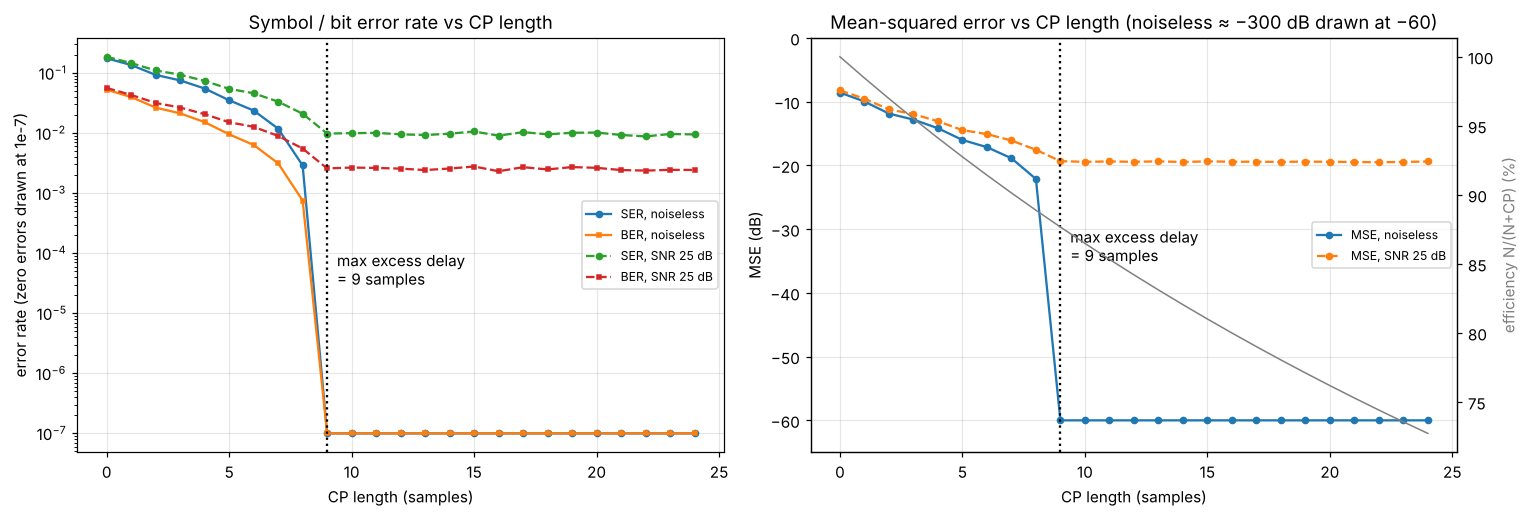

 CP | SER noiseless | MSE noiseless (dB) | SER @25 dB | MSE @25 dB (dB) | efficiency
  0 |      1.76e-01 |               -8.6 |   1.86e-01 |            -8.2 |     100.0%
  1 |      1.36e-01 |              -10.0 |   1.46e-01 |            -9.5 |      98.5%
  2 |      9.30e-02 |              -11.9 |   1.10e-01 |           -11.2 |      97.0%
  3 |      7.53e-02 |              -12.8 |   9.37e-02 |           -12.0 |      95.5%
  4 |      5.52e-02 |              -14.2 |   7.37e-02 |           -13.1 |      94.1%
  5 |      3.52e-02 |              -16.0 |   5.45e-02 |           -14.5 |      92.8%
  6 |      2.37e-02 |              -17.1 |   4.60e-02 |           -15.1 |      91.4%
  7 |      1.18e-02 |              -18.9 |   3.34e-02 |           -16.1 |      90.1%
  8 |      2.89e-03 |              -22.1 |   2.10e-02 |           -17.5 |      88.9%
  9 |      0.00e+00 |             -308.0 |   9.80e-03 |           -19.3 |      87.7%
 10 |      0.00e+00 |             -308.0 |   9.96e-03 |          

In [11]:
cp_list = np.arange(0, 25)
sweep = {"noiseless": [], "SNR 25 dB": []}
for Lcp in cp_list:
    sweep["noiseless"].append(run_link(Lcp, None, data_bits))
    sweep["SNR 25 dB"].append(run_link(Lcp, 25, data_bits))

FLOOR = 1e-7      # zero values are drawn at this floor so they show on a log axis
MSE_FLOOR_DB = -60  # noiseless MSE after the threshold is ~1e-31 (-300 dB); drawn at -60 dB to keep the axis readable
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
for key, ls in [("noiseless", "-"), ("SNR 25 dB", "--")]:
    ser = np.array([r["ser"] for r in sweep[key]]); ber = np.array([r["ber"] for r in sweep[key]])
    mse = np.array([r["mse"] for r in sweep[key]])
    axes[0].semilogy(cp_list, np.maximum(ser, FLOOR), "o"+ls, ms=4, label=f"SER, {key}")
    axes[0].semilogy(cp_list, np.maximum(ber, FLOOR), "s"+ls, ms=3, label=f"BER, {key}")
    axes[1].plot(cp_list, np.maximum(10*np.log10(np.maximum(mse, 1e-300)), MSE_FLOOR_DB), "o"+ls, ms=4, label=f"MSE, {key}")
for ax in axes:
    ax.axvline(TAU_MAX, color="k", ls=":", lw=1.5)
    ax.text(TAU_MAX+0.4, 3e-5 if ax is axes[0] else -35, f"max excess delay\n= {TAU_MAX} samples")
    ax.set_xlabel("CP length (samples)")
axes[0].set_ylabel("error rate (zero errors drawn at 1e-7)"); axes[0].set_title("Symbol / bit error rate vs CP length")
axes[0].legend(loc="center right", fontsize=8)
axes[1].set_ylabel("MSE (dB)"); axes[1].set_title("Mean-squared error vs CP length (noiseless ≈ −300 dB drawn at −60)")
axes[1].set_ylim(MSE_FLOOR_DB - 5, 0)
ax2 = axes[1].twinx(); ax2.plot(cp_list, 100*N/(N+cp_list), color="gray", lw=1)
ax2.set_ylabel("efficiency N/(N+CP) (%)", color="gray"); ax2.grid(False)
axes[1].legend(loc="center right", fontsize=8)
plt.tight_layout(); plt.savefig(f"{FIG_DIR}/step7b_error_vs_cp.png", bbox_inches="tight"); plt.show()

print(f"{'CP':>3} | {'SER noiseless':>13} | {'MSE noiseless (dB)':>18} | {'SER @25 dB':>10} | {'MSE @25 dB (dB)':>15} | {'efficiency':>10}")
for Lcp, a, b in zip(cp_list, sweep["noiseless"], sweep["SNR 25 dB"]):
    print(f"{Lcp:>3} | {a['ser']:>13.2e} | {10*np.log10(max(a['mse'],1e-300)):>18.1f} | "
          f"{b['ser']:>10.2e} | {10*np.log10(b['mse']):>15.1f} | {100*N/(N+Lcp):>9.1f}%")

## Step 8 — written explanation: why error falls sharply at CP = delay spread and then plateaus

**What the plots show.** With the channel's 9-sample (450 ns) maximum excess delay, the noiseless error rate and MSE fall steadily as the CP grows from 0 to 8 samples.
At exactly **CP = 9** they drop to zero, or to floating-point precision for the MSE, and they stay there for every longer CP. At 25 dB SNR the curves fall to the same
threshold and then flatten at the noise floor. That floor is SER ≈ 1 % rather than zero because 25 dB is the *average* SNR: on the most faded
subcarrier ($|H| = 0.16$, about −16 dB) the zero-forcing equaliser amplifies the noise, so that subcarrier works at only ~9 dB. Making the CP longer does not improve the result, while the efficiency line keeps falling
(88.9 % at CP = 8, 80 % at CP = 16, 72.7 % at CP = 24).

**The CP's two roles explain both effects.**

1. **Guard interval (removes ISI).** The multipath channel smears each symbol over $L_{CP}+N+\tau_{max}$ samples. If $L_{CP} \ge \tau_{max}$, the smeared tail of symbol $m-1$
   ends inside symbol $m$'s prefix, which the receiver throws away. The ISI-leakage plot shows exactly this: leakage into the next FFT window is present for CP = 0 and CP = 4
   and is zero for CP = 16. With a short CP, the last $\tau_{max} - L_{CP}$ samples of the previous symbol's echo land inside the FFT window and act as interference.
2. **Cyclic extension (preserves orthogonality, removes ICI).** Because the prefix is a *copy of the symbol's own tail*, the samples that the delayed paths pull into the window
   come from the same symbol, cyclically shifted. The linear convolution then becomes a circular convolution over the FFT window, which our numerical check confirmed for CP ≥ 9.
   The FFT turns a circular convolution into $Y[k] = H[k]\,X[k]$, so each subcarrier sees only a complex gain that one division undoes, and the subcarriers stay orthogonal.
   With CP < 9 the convolution is no longer circular. Each subcarrier then leaks into its neighbours (inter-carrier interference), which is why the "no CP" constellation is
   a cloud of scattered points rather than tight clusters merely shifted by ISI.

**Why there is a threshold.** The error is caused by the part of the channel response that sticks out beyond the CP. Once that part is zero, nothing is left to remove.
Every sample beyond the delay spread is pure overhead: it lowers throughput and wastes transmit energy (a CP of $L_{CP}$ costs $10\log_{10}\frac{N+L_{CP}}{N}$ dB of SNR,
or about 1 dB for CP = 16). That is why real systems size the CP slightly above the worst delay spread they expect. 802.11a/g uses 0.8 µs for indoor channels,
and LTE's normal CP of ~4.7 µs suits outdoor macro cells.

## Checklist — requirements and evaluation criteria

| Manual item | Where |
|---|---|
| Random bits → Gray-coded QAM (16-QAM; QPSK by setting `M = 4`) | Step 1 |
| N = 64 subcarriers, IFFT to time domain | Steps 0, 2 |
| Adjustable-length CP (copy of tail) | Step 3 (`add_cp(x, Lcp)`) |
| Multipath channel: FIR, 4 taps with stated delays and complex gains, convolved with many consecutive symbols | Step 4 (table + plots), Steps 5–7 (400 back-to-back symbols) |
| Receiver with sufficient CP and receiver with no / insufficient CP on the same channel | Steps 5 and 6 |
| Measurable metric: SER, BER and MSE | Steps 5–7 |
| **Criterion 1 (20 %)** modulator/demodulator verified by a noiseless self-check | Step 2 (max error ≈ 1e-16, PASS) |
| **Criterion 2 (15 %)** correct CP insertion and removal | Step 3 checks + Step 4 circular-convolution check |
| **Criterion 3 (15 %)** realistic, clearly specified channel | Step 4 (802.11-like 450 ns excess delay, RMS delay spread, |H| plot) |
| **Criterion 4 (25 %)** ISI with vs without sufficient CP | Step 6 table, ISI-leakage plot, Step 7a constellations |
| **Criterion 5 (15 %)** error vs CP length, threshold and plateau | Step 7b |
| **Criterion 6 (10 %)** written explanation of guard interval and cyclic extension | Step 8 |

Figures are saved in `figures_2_2/`.

In [12]:
print(sorted(os.listdir(FIG_DIR)))

['step1_constellation.png', 'step2_ifft_symbol.png', 'step3_cp_visualizer.png', 'step4_channel.png', 'step6_isi_leakage.png', 'step7a_constellations.png', 'step7b_error_vs_cp.png']
